In [2]:
#Assignment 5	Implement Matrix Factorization	
#	http://www.quuxlabs.com/blog/2010/09/matrix-factorization-a-simple-tutorial-and-implementation-in-python/	


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# rows = users, columns = items, 0 = not rated
R = np.array([[5, 3, 0, 1],
              [4, 0, 0, 1],
              [1, 1, 0, 5],
              [1, 0, 0, 4],
              [0, 1, 5, 4]], dtype=float)

N, M = R.shape      # N users, M items
K = 2               # number of latent features (Hidden user Preference feature)
print("Ratings matrix:\n", R)

Ratings matrix:
 [[5. 3. 0. 1.]
 [4. 0. 0. 1.]
 [1. 1. 0. 5.]
 [1. 0. 0. 4.]
 [0. 1. 5. 4.]]


In [7]:
np.random.seed(0)
P = np.random.rand(N, K)     # user-feature matrix
Q = np.random.rand(M, K)     # item-feature matrix

#Gradient Descent is an optimization algorithm that updates values repeatedly to reduce prediction error.
alpha = 0.002     # learning rate
beta = 0.02       # regularization
steps = 5000      # Number of training iterations
errors = []       # Stores error values after each iteration 

for step in range(steps):
    for i in range(N):
        for j in range(M):
            if R[i, j] > 0:                       # only known ratings
                e = R[i, j] - np.dot(P[i], Q[j])  # prediction error
                p_old = P[i].copy()
                P[i] += alpha * (2 * e * Q[j] - beta * P[i])
                Q[j] += alpha * (2 * e * p_old - beta * Q[j])

    # total squared error on known ratings
    err = np.sum(((R - P @ Q.T) ** 2)[R > 0])
    errors.append(err)

print("Final error:", errors[-1])

Final error: 0.0031120382700033696


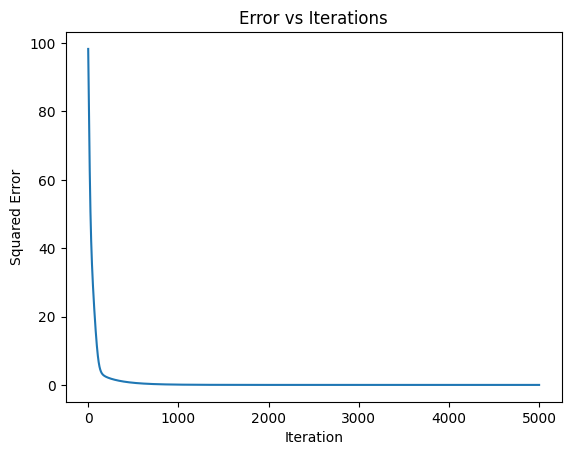

Original R:
 [[5. 3. 0. 1.]
 [4. 0. 0. 1.]
 [1. 1. 0. 5.]
 [1. 0. 0. 4.]
 [0. 1. 5. 4.]]

Predicted R:
 [[4.98 2.98 5.75 1.  ]
 [3.98 2.4  4.8  1.  ]
 [1.01 0.98 5.74 4.97]
 [1.   0.9  4.79 3.98]
 [1.2  1.02 4.98 3.99]]


In [4]:
plt.plot(errors)
plt.xlabel('Iteration')
plt.ylabel('Squared Error')
plt.title('Error vs Iterations')
plt.show()

R_pred = P @ Q.T
print("Original R:\n", R)
print("\nPredicted R:\n", np.round(R_pred, 2))

In [5]:
for i in range(N):
    for j in range(M):
        if R[i, j] == 0:
            print(f"User {i+1}, Item {j+1} -> predicted rating: {R_pred[i, j]:.2f}")

User 1, Item 3 -> predicted rating: 5.75
User 2, Item 2 -> predicted rating: 2.40
User 2, Item 3 -> predicted rating: 4.80
User 3, Item 3 -> predicted rating: 5.74
User 4, Item 2 -> predicted rating: 0.90
User 4, Item 3 -> predicted rating: 4.79
User 5, Item 1 -> predicted rating: 1.20


In [ ]:
The error decreases steadily with iterations and then flattens, which shows the algorithm converges.
The predicted values for known ratings are close to the original ratings, so P and Q capture the rating pattern well.
The empty cells are now filled with predicted ratings, so the model can recommend items a user has not rated yet.
A big matrix is represented by two much smaller matrices (5×2 and 4×2), which shows the dimensionality reduction effect and stores the data compactly.
The result depends on K, α, β and the number of steps. Too large an α makes the error unstable, and too many latent features can overfit on such sparse data.